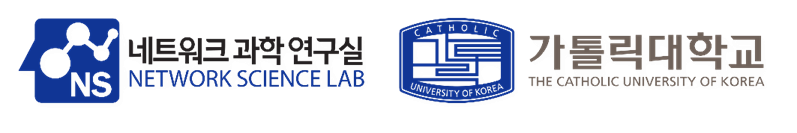

# Week 7: Graph Attention Networks

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W7/SampleCode_7.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### Not all neighbors are equally important

A **GCN** averages a node's neighbors with **fixed** weights that depend only on node degrees. A **Graph Attention Network (GAT)** *learns* how much each neighbor should count, using the neighbors' features. In this notebook we:

1. compute one attention step **by hand** and check it against PyG,
2. compare MLP, GCN, GAT and GATv2 on **Cora** and look inside the learned attention,
3. build two small graphs where attention is **necessary**, to see exactly *when* GAT helps, and why **GATv2** fixes a limitation of the original GAT.

## Table of contents

- [1. Setup](#1-setup)
- [2. From GCN to GAT](#2-from-gcn-to-gat)
- [2.1. One attention step by hand](#21-one-attention-step-by-hand)
- [3. GAT on Cora](#3-gat-on-cora)
- [3.1. Training curves and accuracy](#31-training-curves-and-accuracy)
- [3.2. What do the embeddings look like?](#32-what-do-the-embeddings-look-like)
- [3.3. What did the attention learn?](#33-what-did-the-attention-learn)
- [4. When attention helps: a needle in a haystack](#4-when-attention-helps-a-needle-in-a-haystack)
- [5. GAT vs. GATv2: static vs. dynamic attention](#5-gat-vs-gatv2-static-vs-dynamic-attention)
- [6. Takeaways](#6-takeaways)

## 1. Setup

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric"])

In [2]:
import contextlib
import copy
import io
import tempfile
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # Optional PyG extension notices.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.manifold import TSNE

import torch
import torch.nn.functional as F
import torch_geometric.transforms as T
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv, GATConv, GATv2Conv
from torch_geometric.utils import degree

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

# One color per model, reused in every figure.
MODEL_COLORS = {"MLP": "#9a9a9a", "GCN": "#2a78d6", "GAT": "#eb6834", "GATv2": "#1baf7a"}
CLASS_COLORS = ["#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#8c6d46"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.11.0+cu126 | device: cuda


## 2. From GCN to GAT

Both layers compute a new representation $h_i'$ of node $i$ as a **weighted sum** over its neighbors $\mathcal{N}(i)$ (plus itself). They differ only in **where the weights come from**.

**GCN**: the weight is fixed by the graph structure ($d_i$ = degree of $i$, counting the self-loop):

$$h_i' = \sigma\Big(\sum_{j \in \mathcal{N}(i)\cup\{i\}} \underbrace{\frac{1}{\sqrt{d_i\, d_j}}}_{\text{fixed}}\; W h_j\Big)$$

**GAT** (Veličković et al., 2018): the weight $\alpha_{ij}$ is **computed from the features** of $i$ and $j$:

$$e_{ij} = \text{LeakyReLU}\big(a^\top [\,W h_i \,\|\, W h_j\,]\big), \qquad
\alpha_{ij} = \underbrace{\frac{\exp(e_{ij})}{\sum_{k \in \mathcal{N}(i)\cup\{i\}} \exp(e_{ik})}}_{\text{softmax over the neighbors of } i}, \qquad
h_i' = \sigma\Big(\sum_{j} \alpha_{ij}\, W h_j\Big)$$

* $e_{ij}$ is a raw **score** ("how relevant is $j$ to $i$?"); the softmax turns the scores of $i$'s neighbors into weights that **sum to 1**.
* **Multi-head attention**: run $K$ independent attention heads and concatenate (hidden layers) or average (output layer) their results. This stabilizes training.
* **GATv2** (Brody et al., 2022) moves the non-linearity: $e_{ij} = a^\top \text{LeakyReLU}\big(W [\,h_i \,\|\, h_j\,]\big)$. Section 5 shows why this small change matters.

### 2.1. One attention step by hand

A tiny star graph: node 0 has four neighbors. We compute $e_{0j}$ and $\alpha_{0j}$ from the formula and check them against PyG's `GATConv`. Since $a^\top[Wh_i \| Wh_j] = a_{\text{dst}}^\top W h_i + a_{\text{src}}^\top W h_j$, PyG stores the attention vector $a$ as two halves, `att_dst` and `att_src`.

In [3]:
torch.manual_seed(SEED)
x = torch.randn(5, 3)                                     # 5 nodes, 3 features each
edge_index = torch.tensor([[1, 2, 3, 4],                  # source (neighbor) j
                           [0, 0, 0, 0]])                 # target i = node 0
conv = GATConv(3, 2, heads=1)                             # adds the self-loop 0 -> 0 automatically

# --- by hand ---
neighbors = torch.tensor([0, 1, 2, 3, 4])                 # node 0 itself + its 4 neighbors
Wh = conv.lin(x)                                          # W h_j for every node
score_dst = (Wh * conv.att_dst.view(1, -1)).sum(-1)       # a_dst^T W h_i
score_src = (Wh * conv.att_src.view(1, -1)).sum(-1)       # a_src^T W h_j
e = F.leaky_relu(score_dst[0] + score_src[neighbors], negative_slope=0.2)
alpha = torch.softmax(e, dim=0)

# --- PyG ---
_, (ei, alpha_pyg) = conv(x, edge_index, return_attention_weights=True)
into_0 = ei[1] == 0                                       # PyG also adds self-loops to the leaves
alpha_pyg = alpha_pyg.view(-1)[into_0][ei[0][into_0].argsort()]  # edges j -> 0, ordered by j

# --- GCN for comparison: 1 / sqrt(d_i d_j), node 0 has degree 5, the leaves 2 ---
deg = torch.tensor([5., 2., 2., 2., 2.])
gcn_weight = 1 / (deg[0] * deg[neighbors]).sqrt()

pd.DataFrame({"neighbor j": neighbors.numpy(), "e_0j (hand)": e.detach().numpy(),
              "α_0j (hand)": alpha.detach().numpy(), "α_0j (PyG)": alpha_pyg.detach().numpy(),
              "GCN weight": gcn_weight.numpy()}).round(4).set_index("neighbor j")

,e_0j (hand),α_0j (hand),α_0j (PyG),GCN weight
neighbor j,,,,
0,0.0370,0.0830,0.0830,0.2000
1,0.8705,0.1911,0.1911,0.3162
2,0.9164,0.2000,0.2000,0.3162
3,-0.0845,0.0735,0.0735,0.3162
4,1.7322,0.4523,0.4523,0.3162


Our numbers match PyG exactly. The GCN weights are the same for all four leaves (they have the same degree), whereas GAT gives each neighbor a different weight based on its features. Here the layer is untrained, so these weights are still random; training will make them **useful**.

## 3. GAT on Cora

**Cora** is a citation network: 2,708 papers (nodes), 5,278 citations (edges), a 1,433-dim bag-of-words per paper, and 7 topics (classes). We use the standard split: only **140** labeled nodes for training.

In [4]:
# PyG downloads Cora on first use into a temporary cache: no local data files are needed.
ROOT = f"{tempfile.gettempdir()}/pyg_datasets"
with contextlib.redirect_stderr(io.StringIO()):            # hide PyG's download log
    dataset = Planetoid(ROOT, "Cora", transform=T.NormalizeFeatures())
data = dataset[0].to(DEVICE)

print(f"nodes: {data.num_nodes} | edges: {data.num_edges // 2} | features: {dataset.num_features} "
      f"| classes: {dataset.num_classes}")
print(f"train / val / test nodes: {int(data.train_mask.sum())} / {int(data.val_mask.sum())} "
      f"/ {int(data.test_mask.sum())}")

nodes: 2708 | edges: 5278 | features: 1433 | classes: 7
train / val / test nodes: 140 / 500 / 1000


Four models with the same two-layer shape. Each `forward` returns the **hidden** representation (for plotting later) and the **output** logits. The GAT follows the original paper: 8 heads × 8 hidden units in layer 1 (concatenated to 64), one head in layer 2, dropout 0.6 on both the features and the attention weights.

In [5]:
class MLP(torch.nn.Module):
    """Ignores the graph: a baseline."""
    def __init__(self, dim_in, dim_out, dim_h=64):
        super().__init__()
        self.layer1 = torch.nn.Linear(dim_in, dim_h)
        self.layer2 = torch.nn.Linear(dim_h, dim_out)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.5, training=self.training)
        h = F.elu(self.layer1(x))
        out = self.layer2(F.dropout(h, p=0.5, training=self.training))
        return h, out


class GCN(torch.nn.Module):
    """Fixed neighbor weights 1 / sqrt(d_i d_j)."""
    def __init__(self, dim_in, dim_out, dim_h=64):
        super().__init__()
        self.conv1 = GCNConv(dim_in, dim_h)
        self.conv2 = GCNConv(dim_h, dim_out)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.5, training=self.training)
        h = F.elu(self.conv1(x, edge_index))
        out = self.conv2(F.dropout(h, p=0.5, training=self.training), edge_index)
        return h, out


class GAT(torch.nn.Module):
    """Learned neighbor weights. Pass conv=GATv2Conv to get GATv2."""
    def __init__(self, dim_in, dim_out, dim_h=8, heads=8, conv=GATConv):
        super().__init__()
        self.conv1 = conv(dim_in, dim_h, heads=heads, dropout=0.6)
        self.conv2 = conv(dim_h * heads, dim_out, heads=1, dropout=0.6)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.6, training=self.training)
        h = F.elu(self.conv1(x, edge_index))
        out = self.conv2(F.dropout(h, p=0.6, training=self.training), edge_index)
        return h, out


MODELS = {"MLP": lambda: MLP(dataset.num_features, dataset.num_classes),
          "GCN": lambda: GCN(dataset.num_features, dataset.num_classes),
          "GAT": lambda: GAT(dataset.num_features, dataset.num_classes),
          "GATv2": lambda: GAT(dataset.num_features, dataset.num_classes, conv=GATv2Conv)}
print(MODELS["GAT"]())

GAT(
  (conv1): GATConv(1433, 8, heads=8)
  (conv2): GATConv(64, 7, heads=1)
)


In [6]:
def accuracy(model, data, mask):
    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index)[1].argmax(dim=1)
    return (pred[mask] == data.y[mask]).float().mean().item()


def train(model, data, epochs=200):
    """Train with Adam, keep the weights of the best validation epoch, return the history."""
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
    history, best_val, best_state = [], 0, None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        _, out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        val_acc = accuracy(model, data, data.val_mask)
        history.append({"epoch": epoch, "loss": loss.item(), "val_acc": val_acc})
        if val_acc >= best_val:
            best_val, best_state = val_acc, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

### 3.1. Training curves and accuracy

We train every model with **5 different seeds** and report mean ± std of the test accuracy. The models and curves from the first seed are kept for the plots below.

In [7]:
NUM_RUNS = 5
results, histories, trained = [], {}, {}
for name, make_model in MODELS.items():
    for seed in range(NUM_RUNS):
        torch.manual_seed(seed)
        model = make_model().to(DEVICE)
        history = train(model, data)
        results.append({"model": name, "seed": seed, "test_acc": accuracy(model, data, data.test_mask)})
        if seed == 0:
            histories[name], trained[name] = history, model

results = pd.DataFrame(results)
summary = results.groupby("model", sort=False)["test_acc"].agg(["mean", "std"])
summary.style.format("{:.3f}").set_caption(f"Cora test accuracy over {NUM_RUNS} seeds")

,mean,std
model,,
MLP,0.579,0.008
GCN,0.826,0.008
GAT,0.831,0.004
GATv2,0.837,0.003


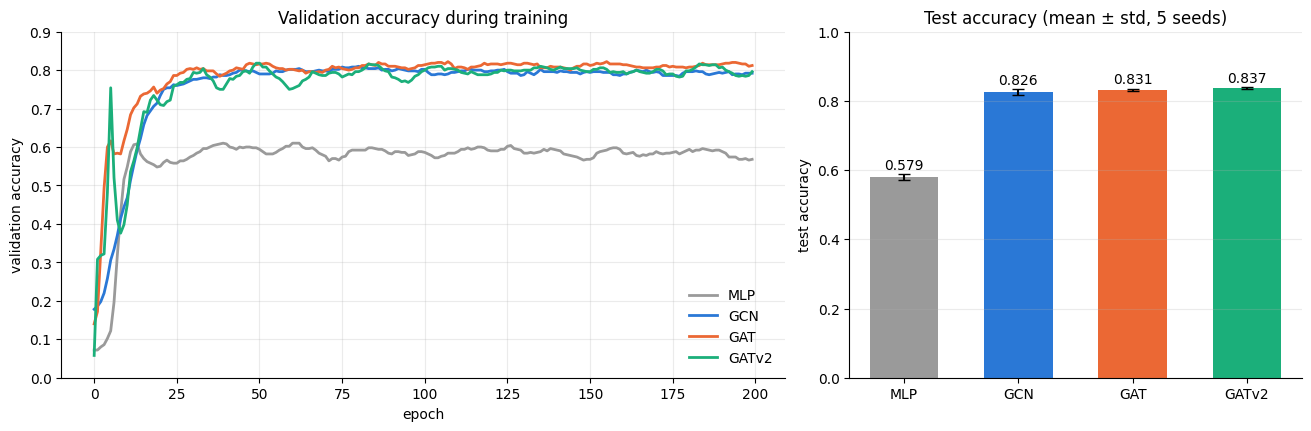

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True,
                               gridspec_kw={"width_ratios": [1.6, 1]})
for name, history in histories.items():
    ax1.plot(history["epoch"], history["val_acc"], color=MODEL_COLORS[name], lw=2, label=name)
ax1.set(xlabel="epoch", ylabel="validation accuracy", ylim=(0, 0.9), title="Validation accuracy during training")
ax1.legend(loc="lower right", frameon=False)

x = np.arange(len(summary))
ax2.bar(x, summary["mean"], yerr=summary["std"], capsize=4, width=0.6,
        color=[MODEL_COLORS[m] for m in summary.index])
for i, (mean, std) in enumerate(summary.itertuples(index=False)):
    ax2.text(i, mean + std + 0.015, f"{mean:.3f}", ha="center")
ax2.set(xticks=x, xticklabels=summary.index, ylim=(0, 1), ylabel="test accuracy",
        title=f"Test accuracy (mean ± std, {NUM_RUNS} seeds)")
ax2.grid(axis="x", visible=False)
plt.show()

* Every graph model beats the MLP by ~25 points: with only 140 labels, the citations carry most of the information.
* GAT and GATv2 are only **slightly** better than GCN on Cora (+0.5 and +1.1 points), and their validation curves are almost on top of GCN's.

So does attention help at all here? Let's look inside.

### 3.2. What do the embeddings look like?

t-SNE projects the **hidden** layer of each model (64-dim) to 2D, with nodes colored by their true class. The raw bag-of-words features are shown for reference.

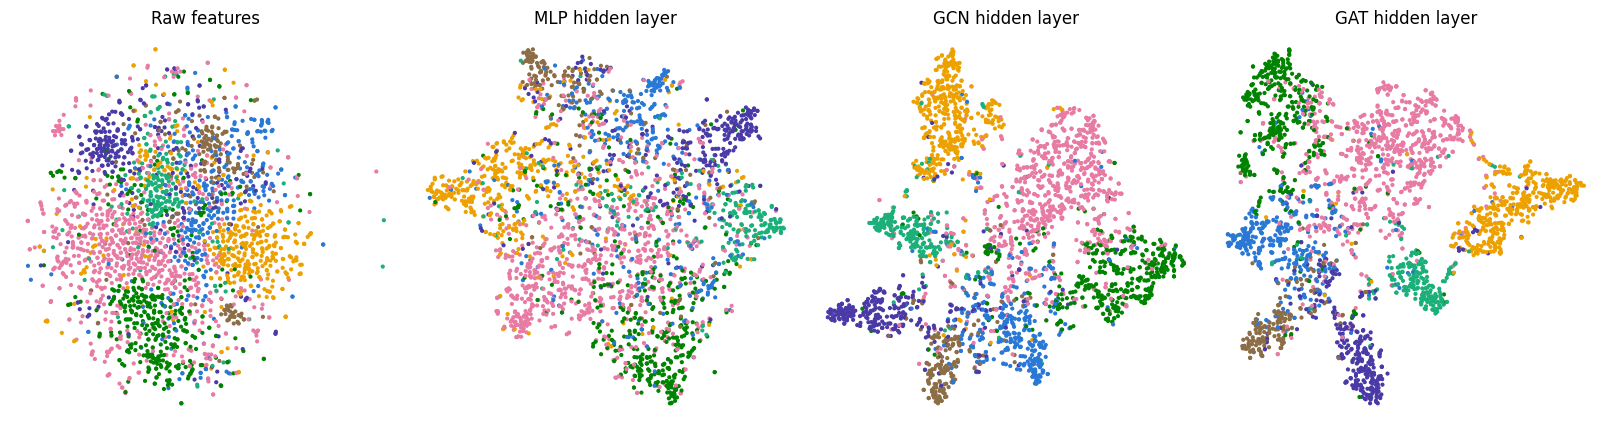

In [9]:
embeddings = {"Raw features": data.x,
              "MLP hidden layer": trained["MLP"](data.x, data.edge_index)[0],
              "GCN hidden layer": trained["GCN"](data.x, data.edge_index)[0],
              "GAT hidden layer": trained["GAT"](data.x, data.edge_index)[0]}
colors = [CLASS_COLORS[c] for c in data.y.cpu()]

with plt.rc_context({"axes.grid": False}):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, (title, emb) in zip(axes, embeddings.items()):
        xy = TSNE(n_components=2, random_state=SEED, init="pca").fit_transform(emb.detach().cpu().numpy())
        ax.scatter(xy[:, 0], xy[:, 1], s=4, c=colors)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

Moving from left to right, the 7 classes separate into clean clusters only once **neighbors are mixed in** (GCN, GAT). The MLP sees just 140 labeled nodes and its own features, so its classes still overlap. GCN and GAT clusters look very similar, consistent with their similar accuracy.

### 3.3. What did the attention learn?

We read the attention weights of the trained GAT's first layer (`return_attention_weights=True`), averaged over the 8 heads. First, a single node: edges are drawn with a width proportional to their weight, for GCN (fixed) and GAT (learned).

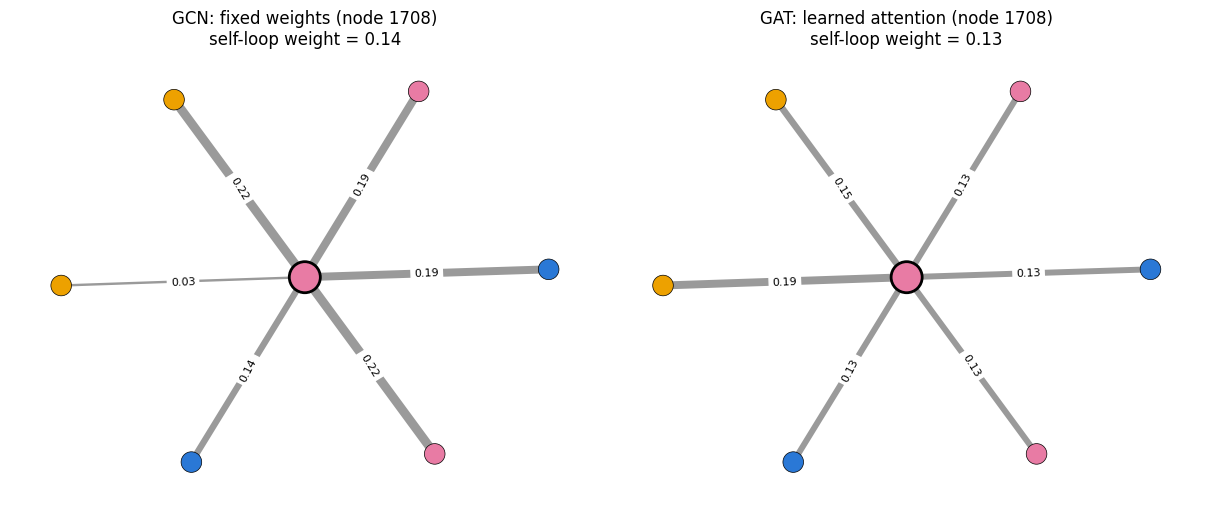

In [10]:
gat = trained["GAT"].eval()
with torch.no_grad():
    _, (att_edges, att) = gat.conv1(data.x, data.edge_index, return_attention_weights=True)
att = att.mean(dim=1)                                       # average over the 8 heads
src, dst = att_edges                                        # att[k] = weight of edge src[k] -> dst[k]
deg = degree(dst, data.num_nodes)                           # degree incl. self-loop


def draw_ego(ax, center, weights, title):
    """Draw node `center` and its neighbors; edge width and label = weight of neighbor -> center."""
    edges = (dst == center).nonzero().view(-1).tolist()
    G = nx.star_graph([center] + [int(src[k]) for k in edges if src[k] != center])
    pos = nx.spring_layout(G, seed=SEED)
    w = {int(src[k]): float(weights[k]) for k in edges}
    nbrs = [n for n in G.nodes if n != center]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9a9a",
                           width=[1 + 25 * w[n] for n in nbrs], edgelist=[(center, n) for n in nbrs])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[500 if n == center else 220 for n in G.nodes],
                           node_color=[CLASS_COLORS[int(data.y[n])] for n in G.nodes],
                           edgecolors="black", linewidths=[2 if n == center else 0.5 for n in G.nodes])
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8,
                                 edge_labels={(center, n): f"{w[n]:.2f}" for n in nbrs})
    ax.set_title(f"{title}\nself-loop weight = {w[center]:.2f}")
    ax.axis("off")


gcn_weights = 1 / (deg[src] * deg[dst]).sqrt()             # what GCN would use on the same edges
# A test node whose neighbors come from more than one class.
center = next(i for i in data.test_mask.nonzero().view(-1).tolist()
              if 6 <= deg[i] <= 10 and len(set(data.y[src[dst == i]].tolist())) >= 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
draw_ego(axes[0], center, gcn_weights, f"GCN: fixed weights (node {center})")
draw_ego(axes[1], center, att, f"GAT: learned attention (node {center})")
plt.show()

Colors are classes; the bold node is the center. GCN's weights vary only because of **degrees** (the neighbor with weight 0.03 is a hub with many citations). GAT's learned weights are all close to the uniform share $1/7 \approx 0.14$. To check whether this is true **everywhere**, we compare each weight to the uniform weight $1/d_i$ that a plain average would use: $\alpha_{ij} \cdot d_i > 1$ means *more* attention than uniform, $< 1$ means *less*. We split edges by whether the two endpoints share a class.

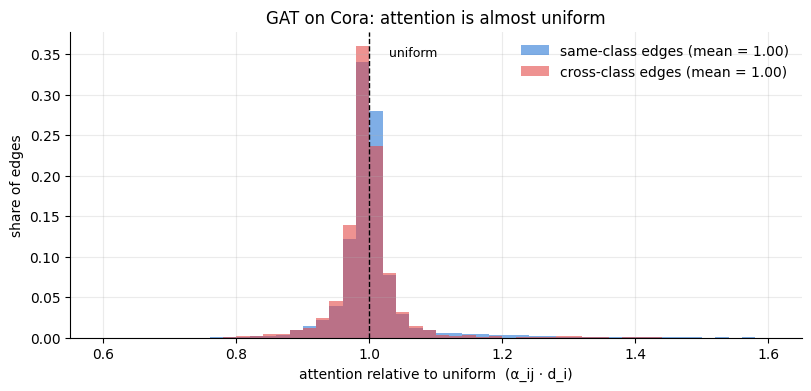

In [11]:
relative = (att * deg[dst]).cpu()                          # 1.0 = exactly uniform attention
not_loop = (src != dst).cpu()
same = (data.y[src] == data.y[dst]).cpu() & not_loop
cross = (data.y[src] != data.y[dst]).cpu()

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
bins = np.linspace(0.6, 1.6, 51)
for mask, label, color in [(same, "same-class edges", "#2a78d6"), (cross, "cross-class edges", "#e34948")]:
    ax.hist(relative[mask], bins=bins, color=color, alpha=0.6, label=f"{label} (mean = {relative[mask].mean():.2f})",
            weights=np.ones(int(mask.sum())) / int(mask.sum()))
ax.axvline(1, color="black", ls="--", lw=1)
ax.text(1.03, ax.get_ylim()[1] * 0.92, "uniform", fontsize=9)
ax.set(xlabel="attention relative to uniform  (α_ij · d_i)", ylabel="share of edges",
       title="GAT on Cora: attention is almost uniform")
ax.legend(frameon=False)
plt.show()

Both distributions sit tightly around **1**: on Cora, the trained GAT gives almost every neighbor its **uniform share**, and it does **not** down-weight cross-class neighbors. This is the reason GAT ≈ GCN on this dataset:

* Cora is strongly **homophilous** (Week 6): ~81 % of edges join papers of the same topic, so "average all neighbors" is already a very good rule.
* GATv1's score cannot compare $i$ with $j$ well (Section 5), so it cannot easily learn "attend to neighbors that are *similar to me*".

Attention can only help when **some neighbors are much more useful than others** *and* that usefulness is visible in their features. The next section builds exactly such a graph.

## 4. When attention helps: a needle in a haystack

Each **target** node has no features of its own and must predict one of 4 classes. It has:

* **1 signal neighbor**: features = one-hot of the target's class, plus a flag = 1,
* **k noise neighbors**: features = one-hot of a *random* class, plus a flag = 0.

To be correct, a model must listen to the one neighbor whose flag is 1 and **ignore** the rest. We train a single layer of GCN and of GAT, and grow the number of noise neighbors $k$.

In [12]:
NUM_CLASSES = 4


def make_needle_graph(num_targets, num_noise, seed):
    """Targets are nodes 0..num_targets-1. Every other node points to exactly one target."""
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, NUM_CLASSES, (num_targets,), generator=g)
    targets = torch.arange(num_targets)

    x = [torch.zeros(num_targets, NUM_CLASSES + 1)]                          # targets: no features
    x.append(torch.cat([F.one_hot(y, NUM_CLASSES), torch.ones(num_targets, 1)], 1))  # signal
    for _ in range(num_noise):                                                # noise
        noise = torch.randint(0, NUM_CLASSES, (num_targets,), generator=g)
        x.append(torch.cat([F.one_hot(noise, NUM_CLASSES), torch.zeros(num_targets, 1)], 1))
    x = torch.cat(x).float()

    # Neighbor block b (b = 1 is the signal) contains nodes b*num_targets + t, which point to target t.
    src = torch.arange(num_targets, (num_noise + 2) * num_targets)
    dst = targets.repeat(num_noise + 1)
    return x, torch.stack([src, dst]), y


def fit_one_layer(conv, num_noise, epochs=300):
    """Train a single conv layer on 1000 targets, test on 1000 new ones."""
    x, edge_index, y = [t.to(DEVICE) for t in make_needle_graph(2000, num_noise, seed=0)]
    conv = conv.to(DEVICE)
    optimizer = torch.optim.Adam(conv.parameters(), lr=0.01)
    train_ids, test_ids = torch.arange(1000), torch.arange(1000, 2000)
    for _ in range(epochs):
        optimizer.zero_grad()
        F.cross_entropy(conv(x, edge_index)[train_ids], y[train_ids]).backward()
        optimizer.step()
    with torch.no_grad():
        pred = conv(x, edge_index).argmax(1)
    return conv, (pred[test_ids] == y[test_ids]).float().mean().item(), (x, edge_index)

In [13]:
NOISE_LEVELS = [0, 1, 2, 5, 10, 20, 50]
needle = []
for k in NOISE_LEVELS:
    torch.manual_seed(SEED)
    _, gcn_acc, _ = fit_one_layer(GCNConv(NUM_CLASSES + 1, NUM_CLASSES), k)
    gat, gat_acc, (x, edge_index) = fit_one_layer(GATConv(NUM_CLASSES + 1, NUM_CLASSES), k)
    with torch.no_grad():
        _, (ei, alpha) = gat(x, edge_index, return_attention_weights=True)
    on_signal = alpha.view(-1)[(ei[0] >= 2000) & (ei[0] < 4000)].mean().item()  # signal nodes: 2000..3999
    needle.append({"noise neighbors k": k, "GCN acc": gcn_acc, "GAT acc": gat_acc,
                   "GAT attention on signal": on_signal, "uniform weight": 1 / (k + 2)})
needle = pd.DataFrame(needle).set_index("noise neighbors k")
needle.round(3)

,GCN acc,GAT acc,GAT attention on signal,uniform weight
noise neighbors k,,,,
0,1.000,1.0,0.999,0.500
1,0.597,1.0,0.996,0.333
2,0.559,1.0,0.995,0.250
5,0.454,1.0,0.996,0.143
10,0.436,1.0,0.995,0.083
20,0.383,1.0,0.991,0.045
50,0.317,1.0,0.990,0.019


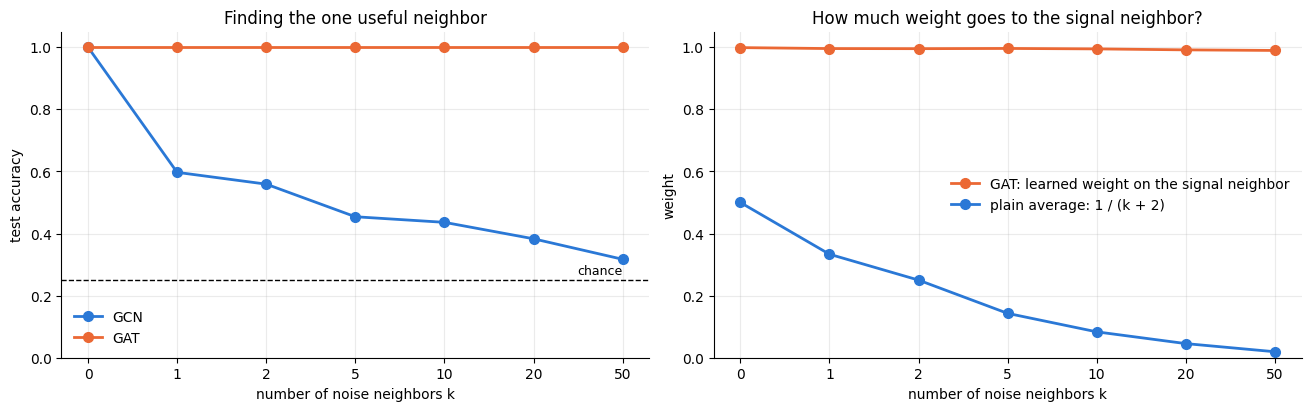

In [14]:
pos = np.arange(len(NOISE_LEVELS))                         # evenly spaced, labeled with k
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for model in ["GCN", "GAT"]:
    ax1.plot(pos, needle[f"{model} acc"], "o-", color=MODEL_COLORS[model], lw=2, ms=7, label=model)
ax1.axhline(1 / NUM_CLASSES, color="black", ls="--", lw=1)
ax1.text(pos[-1], 1 / NUM_CLASSES + 0.02, "chance", ha="right", fontsize=9)
ax1.set(xlabel="number of noise neighbors k", ylabel="test accuracy", ylim=(0, 1.05),
        title="Finding the one useful neighbor")
ax1.legend(frameon=False)

ax2.plot(pos, needle["GAT attention on signal"], "o-", color=MODEL_COLORS["GAT"], lw=2, ms=7,
         label="GAT: learned weight on the signal neighbor")
ax2.plot(pos, needle["uniform weight"], "o-", color=MODEL_COLORS["GCN"], lw=2, ms=7,
         label="plain average: 1 / (k + 2)")
ax2.set(xlabel="number of noise neighbors k", ylabel="weight", ylim=(0, 1.05),
        title="How much weight goes to the signal neighbor?")
ax2.legend(frameon=False, loc="center right")
for ax in (ax1, ax2):
    ax.set_xticks(pos, NOISE_LEVELS)
plt.show()

* **GCN** has to average the signal with the noise. Its accuracy falls as soon as noise appears, and approaches chance as $k$ grows: the signal's share is only $1/(k+2)$.
* **GAT** stays at **100 %** for every $k$. The right panel shows why: it puts almost all of its weight on the signal neighbor, no matter how many noise neighbors there are. It learned the rule "attend to the neighbor whose flag is 1".

A picture of one target with $k = 5$ (signal neighbor drawn with a thick border):

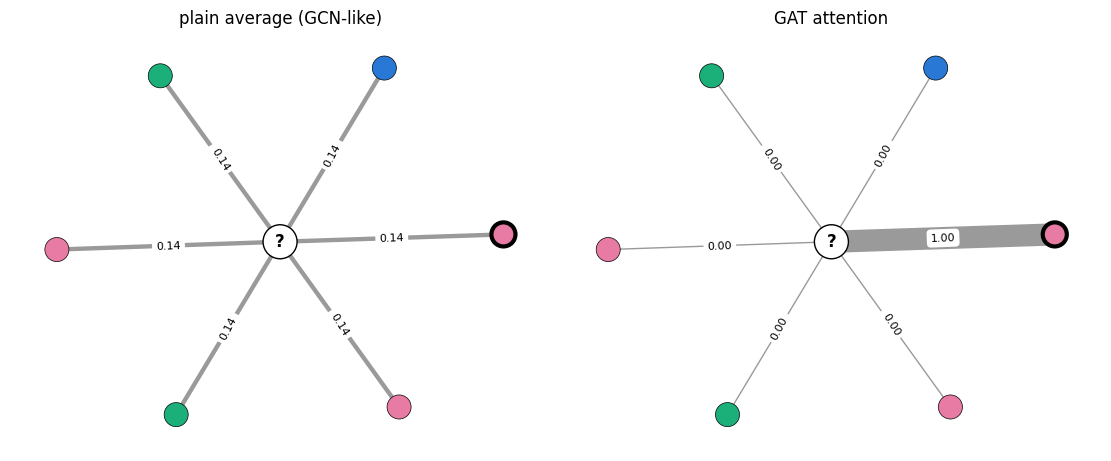

In [15]:
torch.manual_seed(SEED)
gat, _, (x, edge_index) = fit_one_layer(GATConv(NUM_CLASSES + 1, NUM_CLASSES), num_noise=5)
with torch.no_grad():
    _, (ei, alpha) = gat(x, edge_index, return_attention_weights=True)

target = 1000                                              # a test target
signal = 2000 + target                                     # the signal neighbor of target t is node 2000 + t
incoming = (ei[1] == target) & (ei[0] != target)           # skip the self-loop (the target has no features)
nbrs, gat_w = ei[0][incoming].tolist(), alpha.view(-1)[incoming].tolist()
avg_w = [1 / (len(nbrs) + 1)] * len(nbrs)                  # plain average over neighbors + self

G = nx.star_graph([target] + nbrs)
pos = nx.spring_layout(G, seed=SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, title, w in [(axes[0], "plain average (GCN-like)", avg_w), (axes[1], "GAT attention", gat_w)]:
    edges = [(target, v) for v in nbrs]
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color="#9a9a9a", width=[1 + 15 * a for a in w])
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8, edge_labels={e: f"{a:.2f}" for e, a in zip(edges, w)})
    nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=[target] + nbrs, node_size=[600] + [300] * len(nbrs),
                           node_color=["white"] + [CLASS_COLORS[int(x[v, :NUM_CLASSES].argmax())] for v in nbrs],
                           edgecolors="black", linewidths=[1] + [3 if v == signal else 0.5 for v in nbrs])
    nx.draw_networkx_labels(G, pos, ax=ax, labels={target: "?"}, font_weight="bold")
    ax.set_title(title)
    ax.axis("off")
plt.show()

With a plain average, the signal neighbor gets the same small weight as every noise neighbor. GAT gives it nearly **all** the weight, so the target simply copies its class.

## 5. GAT vs. GATv2: static vs. dynamic attention

In GAT the score splits into two separate parts, one for $i$ and one for $j$:

$$e_{ij} = \text{LeakyReLU}\big(\underbrace{a_{\text{dst}}^\top W h_i}_{\text{depends on } i} + \underbrace{a_{\text{src}}^\top W h_j}_{\text{depends on } j}\big)$$

LeakyReLU is monotonic, so the **ranking** of the neighbors $j$ is decided by $a_{\text{src}}^\top W h_j$ alone, and is the **same for every query node** $i$. Brody et al. call this **static attention**: GAT can learn "neighbor $j$ is generally important" (that was enough in Section 4), but not "neighbor $j$ is important *for node $i$*". GATv2 applies $a$ *after* the non-linearity, so $i$ and $j$ interact and the ranking can change with $i$ (**dynamic attention**).

**Test: dictionary lookup.** Each small graph has $K = 8$ **key** nodes and $K$ **query** nodes, and every key points to every query.

* key node $k$: features = [one-hot id $k$, one-hot *value* $v_k$],
* query node $q$: features = [one-hot id $q$, zeros]; it must predict the value $v_q$ of the key with the **same id**.

Every query must attend to a **different** key, which static attention cannot do.

In [16]:
K = 8


def make_lookup_graphs(num_graphs, seed):
    """Many disjoint lookup graphs. Labels of key nodes are -1 (not predicted)."""
    g = torch.Generator().manual_seed(seed)
    ids = torch.eye(K)
    x, edges, y = [], [], []
    for b in range(num_graphs):
        values = torch.randint(0, K, (K,), generator=g)
        keys = torch.cat([ids, F.one_hot(values, K).float()], 1)
        queries = torch.cat([ids, torch.zeros(K, K)], 1)
        offset = 2 * K * b                                  # nodes offset..offset+K-1 are keys, then queries
        src = torch.arange(K).repeat_interleave(K) + offset  # every key ...
        dst = torch.arange(K, 2 * K).repeat(K) + offset      # ... points to every query
        x.append(torch.cat([keys, queries]))
        edges.append(torch.stack([src, dst]))
        y.append(torch.cat([torch.full((K,), -1), values]))
    return torch.cat(x).to(DEVICE), torch.cat(edges, 1).to(DEVICE), torch.cat(y).to(DEVICE)


class LookupNet(torch.nn.Module):
    """One attention layer + a linear classifier."""
    def __init__(self, conv):
        super().__init__()
        self.conv = conv(2 * K, 64, add_self_loops=False)    # queries must read from keys only
        self.out = torch.nn.Linear(64, K)

    def forward(self, x, edge_index):
        return self.out(F.relu(self.conv(x, edge_index)))


train_graphs, test_graphs = make_lookup_graphs(500, seed=0), make_lookup_graphs(200, seed=1)
lookup_models, lookup_curves = {}, {}
for name, conv in [("GAT", GATConv), ("GATv2", GATv2Conv)]:
    torch.manual_seed(SEED)
    model = LookupNet(conv).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    x, edge_index, y = train_graphs
    curve = []
    for epoch in range(600):
        model.train()
        optimizer.zero_grad()
        F.cross_entropy(model(x, edge_index)[y >= 0], y[y >= 0]).backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            xt, eit, yt = test_graphs
            curve.append((model(xt, eit).argmax(1)[yt >= 0] == yt[yt >= 0]).float().mean().item())
    lookup_models[name], lookup_curves[name] = model, curve
    print(f"{name:>5}: test accuracy = {curve[-1]:.3f}")

  GAT: test accuracy = 0.337


GATv2: test accuracy = 1.000


We now look at the attention of both models on **one test graph**: row = query node, column = key node. The correct key for each query is on the **diagonal** (outlined).

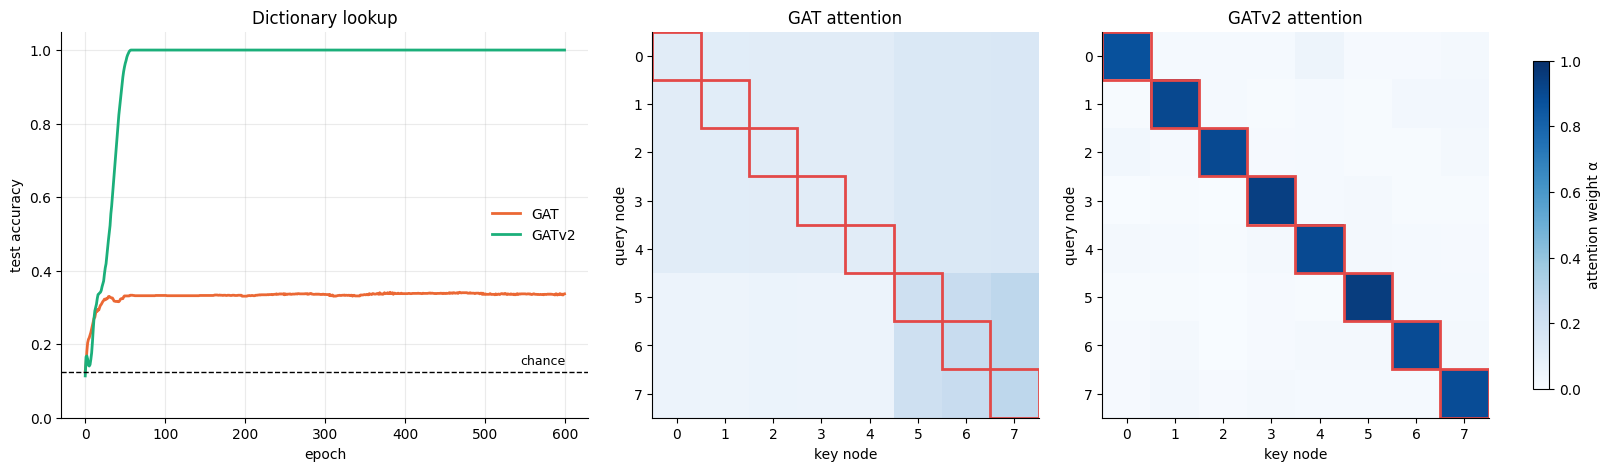

In [17]:
xt, eit, yt = test_graphs

with plt.rc_context({"axes.grid": False}):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True,
                             gridspec_kw={"width_ratios": [1.2, 1, 1]})
    for name, curve in lookup_curves.items():
        axes[0].plot(curve, color=MODEL_COLORS[name], lw=2, label=name)
    axes[0].axhline(1 / K, color="black", ls="--", lw=1)
    axes[0].text(600, 1 / K + 0.02, "chance", ha="right", fontsize=9)
    axes[0].set(xlabel="epoch", ylabel="test accuracy", ylim=(0, 1.05), title="Dictionary lookup")
    axes[0].grid(alpha=0.25)
    axes[0].legend(frameon=False)

    for ax, (name, model) in zip(axes[1:], lookup_models.items()):
        with torch.no_grad():
            _, (ei, alpha) = model.conv(xt, eit, return_attention_weights=True)
        A = torch.zeros(K, K)
        keep = (ei[0] < 2 * K) & (ei[1] < 2 * K)
        A[ei[1][keep] - K, ei[0][keep]] = alpha.view(-1)[keep].cpu()   # A[query, key]
        im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
        for i in range(K):
            ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, ec="#e34948", lw=2))
        ax.set(title=f"{name} attention", xlabel="key node", ylabel="query node",
               xticks=range(K), yticks=range(K))
    fig.colorbar(im, ax=axes[1:], shrink=0.85, label="attention weight α")
    plt.show()

* **GAT** gets stuck at about **34 %** (chance is 12.5 %). In its heatmap every row ranks the keys in the **same order** (keys 5–7 always on top), and the weights are nearly flat. That is static attention, exactly as the formula predicts: a query cannot single out *its own* key, so it mostly gets a blurred mix of all values.
* **GATv2** reaches **100 %** and its attention is concentrated on the **diagonal**: each query attends to its own key.

On Cora both models scored about the same, because that task does not require query-dependent attention. GATv2 is a safe default: it costs about the same and is strictly more expressive.

## 6. Takeaways

* **GCN** weights neighbors by degree only; **GAT** learns a weight $\alpha_{ij}$ for every edge from the node features, normalized with a softmax over the neighbors.
* On a **homophilous** graph like Cora, uniform averaging is already good, so GAT ends up with **near-uniform** attention and only small gains over GCN.
* Attention pays off when **neighbors differ in usefulness** and that is visible in their features. In the needle-in-a-haystack task, GCN drops toward chance while GAT stays at 100 % by putting almost all its weight on the right neighbor.
* Original GAT has **static** attention: every node ranks the neighbors the same way. **GATv2** fixes this with one change (non-linearity before $a$) and solves tasks where *who matters depends on who is asking*.
* `return_attention_weights=True` in PyG lets you inspect the learned $\alpha_{ij}$; always look before assuming that attention "explains" a prediction.

### Further reading
- Veličković, Cucurull, Casanova, Romero, Liò & Bengio. *Graph Attention Networks.* ICLR 2018.
- Brody, Alon & Yahav. *How Attentive are Graph Attention Networks?* ICLR 2022.
- Knyazev, Taylor & Amer. *Understanding Attention and Generalization in Graph Neural Networks.* NeurIPS 2019.